# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [3]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)
    
    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))            
        
            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")
            
            print("Please enter a valid move.")
            

    return(move)

## Start an interactive game as x

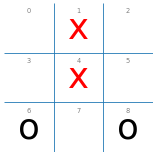

Available actions are: [0, 2, 3, 5, 7]


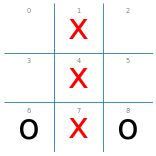

{'x': 1, 'o': 0, 'd': 0}

In [8]:
play(interactive_player, random_player, N = 1,  show_final_board=True)

> **Ghi chú (thêm vào):** ô trên gọi `input()` nên cần người ngồi nhập nước đi trong JupyterLab – kết quả hiển thị ngay phía trên là của lần chơi gốc do giảng viên lưu lại. Khi chạy tự động (không có người nhập) ô này không thể chạy được, vì vậy phần **Bài 7** ở cuối notebook chạy lại chính hàm `interactive_player` nhưng với các nước đi của "người chơi" được nạp sẵn.

### Start an interactive game as o

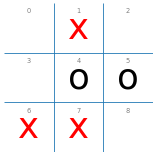

Available actions are: [0, 2, 3, 8]


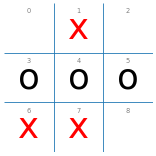

{'x': 0, 'o': 1, 'd': 0}

In [7]:
play(random_player, interactive_player, N = 1, show_final_board = True)

> **Ghi chú (thêm vào):** tương tự ô trên – ô này cần nhập tay. Xem phần **Bài 7** ở cuối notebook để thấy các ván đã được ghi lại ở cả hai vai X và O.

---
# Lab 05 – Bài 7: Chơi Tic-Tac-Toe tương tác với một tác tử đã xây dựng ở các phần trước

> Yêu cầu: chạy `interactive_player()`, chơi với một tác tử đã xây dựng (cả vai X và O), **ghi lại ít nhất một ván** và **nhận xét chiến lược của tác tử**.
>
> **Lưu ý quan trọng về cách chạy:** notebook này được chạy tự động nên không có người ngồi gõ nước đi. Vì vậy các nước đi của "người chơi" được **nạp sẵn**: hàm `interactive_player` của giảng viên vẫn được gọi **nguyên vẹn** (vẫn vẽ bàn cờ, in danh sách nước hợp lệ và gọi `input()`), nhưng `input()` được thay tạm thời bằng một chính sách soạn sẵn (được in ra ngay sau dấu nhắc, như khi người dùng gõ). Hai "người chơi" được dùng:
> * **người chơi cẩn thận** – thắng ngay nếu có thể > chặn đối thủ > ô giữa > góc > cạnh (cách chơi của người biết luật chơi cơ bản);
> * **người chơi bất cẩn** – bỏ qua đe dọa của đối thủ (chỉ thắng nếu có thể), ưu tiên các ô cạnh (mô phỏng người mới chơi hay mắc lỗi).
>
> Tác tử được thử: **Alpha-Beta** (tối ưu) và **Pure Monte Carlo Search với N = 1000** (xấp xỉ, ngẫu nhiên; đặt seed để tái lập). Bạn có thể tự chơi bằng cách chạy ô 8 và ô 10 ở trên (nhập nước đi bằng tay) hoặc đổi `human_careful` thành `interactive_player` trong các ô bên dưới.

In [4]:
import math, contextlib
from functools import lru_cache
from unittest import mock
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tictactoe
from tictactoe import check_board
from IPython.display import Markdown

# ---------- Các tác tử đã xây dựng ở các phần trước (mã giống notebook Alpha-Beta và Pure Monte Carlo Search) ----------
def alpha_beta_search(board, player = 'x'):
    """Alpha-Beta (giống tictactoe_alpha_beta_tree_search.ipynb, bỏ phần in/đếm nút)."""
    def max_value_ab(state, alpha, beta):
        v = utility(state, player)
        if v is not None: return v, None
        v, move = -math.inf, None
        for a in actions(state):
            v2, _ = min_value_ab(result(state, player, a), alpha, beta)
            if v2 > v:
                v, move = v2, a
                alpha = max(alpha, v)
            if v >= beta: return v, move
        return v, move
    def min_value_ab(state, alpha, beta):
        v = utility(state, player)
        if v is not None: return v, None
        v, move = +math.inf, None
        for a in actions(state):
            v2, _ = max_value_ab(result(state, other(player), a), alpha, beta)
            if v2 < v:
                v, move = v2, a
                beta = min(beta, v)
            if v <= alpha: return v, move
        return v, move
    value, move = max_value_ab(board, -math.inf, +math.inf)
    return {"move": move, "value": value}

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, player)["move"]

def playout(state, action, player = 'x'):
    state = result(state, player, action)
    current_player = other(player)
    while True:
        u = utility(state, player)
        if u is not None: return u
        state = result(state, current_player, np.random.choice(actions(state)))
        current_player = other(current_player)

def pmcs(board, N = 100, player = 'x'):
    acts = actions(board)
    n = math.floor(N / len(acts))
    ps = {i: np.mean([playout(board, i, player) for _ in range(n)]) for i in acts}
    return max(ps, key = ps.get)

def pmcs1000_player(board, player = 'x'):
    return pmcs(board, N = 1000, player = player)

# ---------- "Người chơi" được nạp sẵn nước đi ----------
LINES = [(0,1,2), (3,4,5), (6,7,8), (0,3,6), (1,4,7), (2,5,8), (0,4,8), (2,4,6)]
def completing_move(board, who):
    """ô còn trống giúp `who` hoàn thành một hàng (nếu có)."""
    for l in LINES:
        cells = [board[i] for i in l]
        if cells.count(who) == 2 and cells.count(' ') == 1:
            return l[cells.index(' ')]
    return None

def human_careful(board, me):
    m = completing_move(board, me)                         # 1. thắng ngay
    if m is None: m = completing_move(board, other(me))    # 2. chặn đối thủ
    if m is not None: return m
    return next(c for c in (4, 0, 2, 6, 8, 1, 3, 5, 7) if board[c] == ' ')   # 3. giữa > góc > cạnh

def human_careless(board, me):
    m = completing_move(board, me)                         # chỉ thắng nếu có thể, KHÔNG chặn đối thủ
    if m is not None: return m
    return next(c for c in (1, 3, 5, 7, 0, 2, 6, 8, 4) if board[c] == ' ')   # ưu tiên cạnh

def scripted_human(policy):
    """Gọi nguyên vẹn interactive_player, nhưng câu trả lời cho input() do `policy` quyết định."""
    def agent(board, player):
        def fake_input(prompt = ""):
            move = policy(board, player)
            print(f"{prompt}{move}")                       # in ra như khi người dùng gõ nước đi
            return str(move)
        with mock.patch("builtins.input", fake_input):
            return interactive_player(board, player)
    return agent

@contextlib.contextmanager
def keep_output(show_boards = False):
    """interactive_player gọi clear_output() ở mỗi lượt nên lịch sử ván đấu sẽ bị xóa; tạm tắt nó để GHI LẠI cả ván."""
    g = globals()
    saved = {k: g[k] for k in ("clear_output", "show_board")}
    g["clear_output"] = lambda *a, **k: None
    if not show_boards: g["show_board"] = lambda *a, **k: None
    try: yield
    finally: g.update(saved)

def play_recorded(x, o):
    board, hist, turn = empty_board(), [], 'x'
    agents = {'x': x, 'o': o}
    while True:
        a = int(agents[turn](board, turn))
        board = result(board, turn, a)
        hist.append((turn, a))
        w = str(check_board(board))
        if w != 'n': return hist, board, w
        turn = other(turn)

GAMES = {}
def run_game(key, title, x, o, human_role, agent_name, seed = None, show_boards = False):
    if seed is not None: np.random.seed(seed)
    print(f"\n===== {key}: {title} =====")
    with keep_output(show_boards):
        hist, board, w = play_recorded(x, o)
    GAMES[key] = dict(title = title, hist = hist, board = board, winner = w, human_role = human_role, agent = agent_name)
    kq = {"x": "X thắng", "o": "O thắng", "d": "hòa"}[w]
    print("\n→ Ghi lại:", " ".join(f"{p}{a}" for p, a in hist), f"| kết quả: {kq}")
print("Đã sẵn sàng.")

Đã sẵn sàng.


## Ván G1 – chạy `interactive_player` nguyên vẹn: người chơi cẩn thận (X) vs. Alpha-Beta (O)

Ván đầu được chạy với **bàn cờ hiển thị ở mỗi lượt** (đúng giao diện của `interactive_player`: bàn cờ, danh sách nước hợp lệ, dấu nhắc và nước đi được nhập). Các ván sau ẩn bàn cờ cho gọn và được tổng hợp bằng hình ở cuối.


===== G1: Người (X, cẩn thận) vs. Alpha-Beta (O) =====


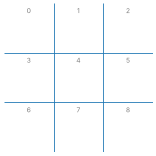

Available actions are: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
4


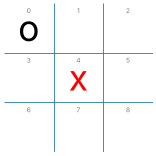

Available actions are: [1, 2, 3, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
2


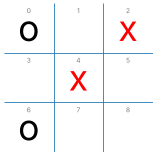

Available actions are: [1, 3, 5, 7, 8]
Your move (0-8 or -1 to end the game):
3


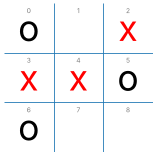

Available actions are: [1, 7, 8]
Your move (0-8 or -1 to end the game):
8


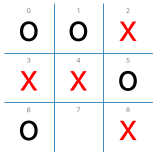

Available actions are: [7]
Your move (0-8 or -1 to end the game):
7

→ Ghi lại: x4 o0 x2 o6 x3 o5 x8 o1 x7 | kết quả: hòa


In [5]:
run_game("G1", "Người (X, cẩn thận) vs. Alpha-Beta (O)", scripted_human(human_careful), alpha_beta_player,
         human_role = 'x', agent_name = "Alpha-Beta", show_boards = True)

## Các ván còn lại – thử cả vai X và O, hai tác tử khác nhau

In [6]:
run_game("G2", "Người (O, cẩn thận) vs. Alpha-Beta (X)",      alpha_beta_player, scripted_human(human_careful), 'o', "Alpha-Beta")
run_game("G3", "Người (X, bất cẩn) vs. Alpha-Beta (O)",       scripted_human(human_careless), alpha_beta_player, 'x', "Alpha-Beta")
run_game("G4", "Người (X, cẩn thận) vs. PMCS-1000 (O)",       scripted_human(human_careful), pmcs1000_player, 'x', "PMCS (N = 1000)", seed = 2026)
run_game("G5", "Người (O, cẩn thận) vs. PMCS-1000 (X)",       pmcs1000_player, scripted_human(human_careful), 'o', "PMCS (N = 1000)", seed = 2026)


===== G2: Người (O, cẩn thận) vs. Alpha-Beta (X) =====


Available actions are: [1, 2, 3, 4, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
4
Available actions are: [2, 3, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
2
Available actions are: [3, 5, 7, 8]
Your move (0-8 or -1 to end the game):
3
Available actions are: [7, 8]
Your move (0-8 or -1 to end the game):
8

→ Ghi lại: x0 o4 x1 o2 x6 o3 x5 o8 x7 | kết quả: hòa

===== G3: Người (X, bất cẩn) vs. Alpha-Beta (O) =====
Available actions are: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
1
Available actions are: [2, 3, 4, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
3
Available actions are: [2, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
5
Available actions are: [6, 7, 8]
Your move (0-8 or -1 to end the game):
7

→ Ghi lại: x1 o0 x3 o4 x5 o2 x7 o6 | kết quả: O thắng

===== G4: Người (X, cẩn thận) vs. PMCS-1000 (O) =====
Available actions are: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
4


Available actions are: [0, 1, 2, 3, 5, 6, 7]
Your move (0-8 or -1 to end the game):
0
Available actions are: [1, 3, 5, 6, 7]
Your move (0-8 or -1 to end the game):
5
Available actions are: [1, 3, 6]
Your move (0-8 or -1 to end the game):
3

→ Ghi lại: x4 o8 x0 o2 x5 o7 x3 | kết quả: X thắng

===== G5: Người (O, cẩn thận) vs. PMCS-1000 (X) =====


Available actions are: [0, 1, 2, 3, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
0
Available actions are: [1, 2, 5, 6, 7, 8]
Your move (0-8 or -1 to end the game):
5
Available actions are: [1, 6, 7, 8]
Your move (0-8 or -1 to end the game):
6
Available actions are: [7, 8]
Your move (0-8 or -1 to end the game):
7

→ Ghi lại: x4 o0 x3 o5 x2 o6 x1 o7 x8 | kết quả: hòa


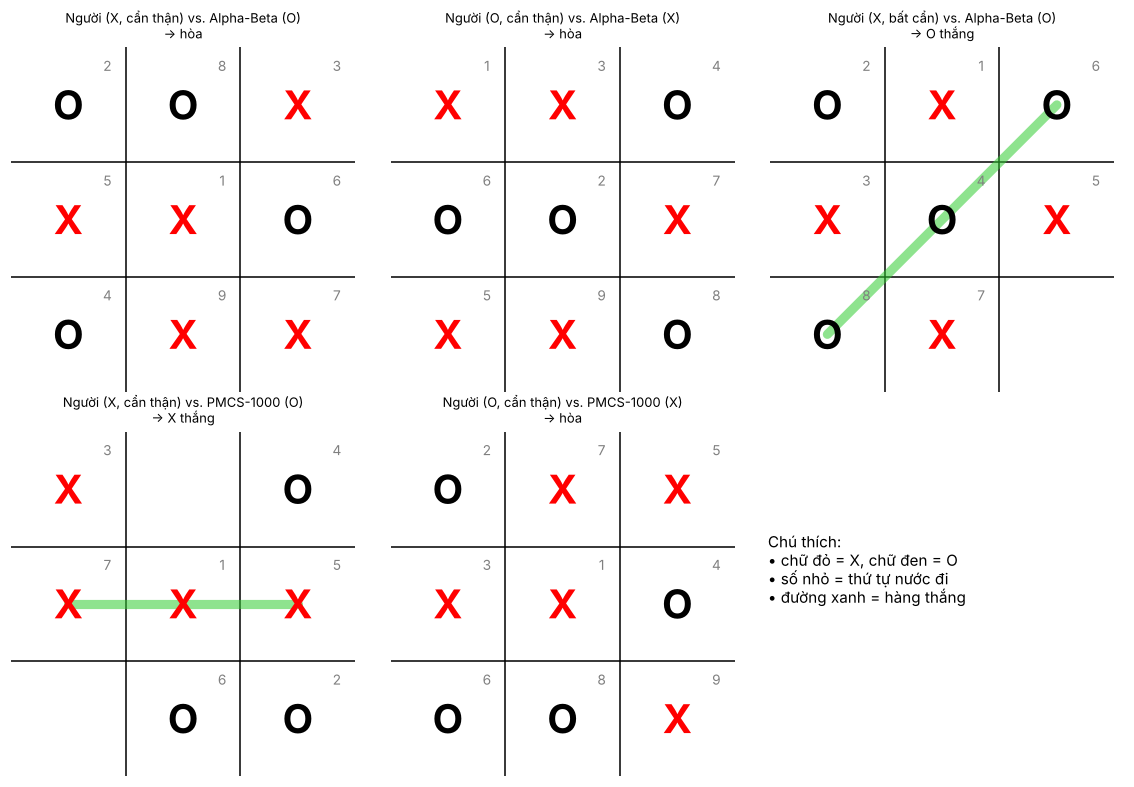

In [7]:
# ---------- Hình tổng hợp các ván đã ghi (số nhỏ = thứ tự nước đi) ----------
def winning_line(board):
    for l in LINES:
        if board[l[0]] != ' ' and board[l[0]] == board[l[1]] == board[l[2]]: return l
    return None

def draw_game(ax, g):
    ax.set_xlim(-.5, 2.5); ax.set_ylim(2.5, -.5); ax.set_aspect("equal"); ax.axis("off")
    for k in (.5, 1.5):
        ax.plot([k, k], [-.5, 2.5], color = "k", lw = 1); ax.plot([-.5, 2.5], [k, k], color = "k", lw = 1)
    for ply, (p, a) in enumerate(g["hist"], 1):
        r, c = divmod(a, 3)
        ax.text(c, r, p.upper(), ha = "center", va = "center", fontsize = 26, fontweight = "bold", color = "red" if p == "x" else "black")
        ax.text(c + .34, r - .34, str(ply), ha = "center", va = "center", fontsize = 9, color = "gray")
    wl = winning_line(g["board"])
    if wl:
        (r0, c0), (r1, c1) = divmod(wl[0], 3), divmod(wl[2], 3)
        ax.plot([c0, c1], [r0, r1], color = "limegreen", lw = 6, alpha = .55, solid_capstyle = "round")
    kq = {"x": "X thắng", "o": "O thắng", "d": "hòa"}[g["winner"]]
    ax.set_title(f"{g['title']}\n→ {kq}", fontsize = 8.5)

fig, axes = plt.subplots(2, 3, figsize = (10.5, 7.2), dpi = 110)
for ax, key in zip(axes.flat, ["G1", "G2", "G3", "G4", "G5"]):
    draw_game(ax, GAMES[key])
axes.flat[-1].axis("off")
axes.flat[-1].text(0.02, 0.6, "Chú thích:\n• chữ đỏ = X, chữ đen = O\n• số nhỏ = thứ tự nước đi\n• đường xanh = hàng thắng", fontsize = 10, va = "center")
plt.tight_layout(); plt.show()

In [8]:
# ---------- Phân tích từng nước đi của tác tử bằng bộ giải Minimax chính xác ----------
@lru_cache(maxsize = None)
def solve(state, mover):
    g = check_board(list(state))
    if g == 'x': return 1
    if g == 'o': return -1
    if g == 'd': return 0
    vals = []
    for a in actions(list(state)):
        c = list(state); c[a] = mover
        vals.append(solve(tuple(c), other(mover)))
    return max(vals) if mover == 'x' else min(vals)

def explain(key):
    g = GAMES[key]
    agent_role = other(g["human_role"])
    board, rows = empty_board(), []
    for ply, (p, a) in enumerate(g["hist"], 1):
        if p == agent_role:
            sign = 1 if p == 'x' else -1
            vals = {m: sign * solve(tuple(result(board, p, m)), other(p)) for m in actions(board)}
            best = max(vals.values())
            wins = [m for m in vals if check_board(result(board, p, m)) == p]       # nước thắng ngay
            rows.append({"Ván": key, "Nước thứ": ply, "Tác tử": g["agent"], "Nước chọn": a, "Giá trị nước chọn": vals[a],
                         "Giá trị tốt nhất": best, "Các nước tối ưu": [m for m in vals if vals[m] == best],
                         "Thắng ngay có sẵn": wins, "Sai lầm": vals[a] < best})
        board = result(board, p, a)
    return pd.DataFrame(rows)

analysis = pd.concat([explain(k) for k in GAMES], ignore_index = True)
display(analysis)

,Ván,Nước thứ,Tác tử,Nước chọn,Giá trị nước chọn,Giá trị tốt nhất,Các nước tối ưu,Thắng ngay có sẵn,Sai lầm
0,G1,2,Alpha-Beta,0,0,0,"[0, 2, 6, 8]",[],False
1,G1,4,Alpha-Beta,6,0,0,[6],[],False
2,G1,6,Alpha-Beta,5,0,0,[5],[],False
3,G1,8,Alpha-Beta,1,0,0,"[1, 7]",[],False
4,G2,1,Alpha-Beta,0,0,0,"[0, 1, 2, 3, 4, 5, 6, 7, 8]",[],False
5,G2,3,Alpha-Beta,1,0,0,"[1, 2, 3, 5, 6, 7, 8]",[],False
6,G2,5,Alpha-Beta,6,0,0,[6],[],False
7,G2,7,Alpha-Beta,5,0,0,[5],[],False
8,G2,9,Alpha-Beta,7,0,0,[7],[],False
9,G3,2,Alpha-Beta,0,0,0,"[0, 2, 4, 7]",[],False


In [9]:
# ---------- Nhận xét tự động về chiến lược của tác tử (từ các ván vừa ghi) ----------
kq = lambda w: {"x": "X thắng", "o": "O thắng", "d": "hòa"}[w]
val = lambda v: {1: "+1, tức thắng", 0: "0, tức hòa", -1: "−1, tức thua"}[int(v)]
cells = lambda L: ", ".join(f"ô {m}" for m in L)
G = GAMES
ab = analysis[analysis["Tác tử"] == "Alpha-Beta"]
pm = analysis[analysis["Tác tử"] != "Alpha-Beta"]
ab_open = G["G2"]["hist"][0][1]                                  # nước mở đầu của Alpha-Beta khi đi trước
ab_reply = G["G1"]["hist"][1][1]                                 # nước đáp của Alpha-Beta (O) khi X mở ô giữa
ab_opt_open = analysis[(analysis["Ván"] == "G2") & (analysis["Nước thứ"] == 1)]["Các nước tối ưu"].iloc[0]
delayed = ab[(ab["Thắng ngay có sẵn"].map(len) > 0) & (~ab.apply(lambda r: r["Nước chọn"] in r["Thắng ngay có sẵn"], axis = 1))]
mistakes = pm[pm["Sai lầm"]]

lines = []
lines.append(f"* **Alpha-Beta chơi tối ưu:** {int(ab['Sai lầm'].sum())} nước sai trong {len(ab)} nước đã phân tích. G1 = {kq(G['G1']['winner'])}, G2 = {kq(G['G2']['winner'])} (người chơi cẩn thận cũng không mắc lỗi nên hòa) và G3 = {kq(G['G3']['winner'])} (người bất cẩn không chặn đe dọa nên bị thua).")
lines.append(f"* **Chọn nước theo thứ tự chỉ số:** khi nhiều nước có giá trị như nhau, Alpha-Beta lấy nước đầu tiên (chỉ số nhỏ nhất). Ví dụ khi đi trước nó luôn mở ở ô {ab_open} (cả {len(ab_opt_open)} nước mở đầu đều có giá trị 0) và khi X mở ô giữa nó đáp ô {ab_reply}. Cách chơi vì thế **xác định và dễ đoán**; nó không biết đặt bẫy để dụ đối thủ sai (khác với PMCS nhắm vào đối thủ ngẫu nhiên).")
if len(delayed):
    r = delayed.iloc[0]
    lines.append(f"* **Không ưu tiên thắng nhanh:** utility chỉ là +1/0/−1 (không tính độ sâu) nên mọi nước thắng đều bằng nhau. Ở ván {r['Ván']}, nước thứ {r['Nước thứ']} Alpha-Beta có thể thắng ngay bằng {cells(r['Thắng ngay có sẵn'])} nhưng chọn ô {r['Nước chọn']} (vẫn thắng chắc nhưng chậm hơn một nước) vì ô này đứng trước theo chỉ số. Cách khắc phục: trừ điểm theo độ sâu hoặc xếp nước thắng ngay lên đầu (move ordering).")
else:
    lines.append("* Trong các ván ghi lại, mỗi khi có nước thắng ngay Alpha-Beta đều chọn nước đó.")
if len(mistakes):
    r = mistakes.iloc[0]
    lines.append(f"* **PMCS (N = 1000) không đảm bảo tối ưu:** trong {len(pm)} nước đã phân tích PMCS mắc {len(mistakes)} sai lầm. Ví dụ ván {r['Ván']}, nước thứ {r['Nước thứ']}: PMCS chọn ô {r['Nước chọn']} (giá trị {val(r['Giá trị nước chọn'])}) thay vì {cells(r['Các nước tối ưu'])} (giá trị {val(r['Giá trị tốt nhất'])}) – kết quả {kq(G[r['Ván']]['winner'])}. Nguyên nhân: playout giả định đối thủ chơi ngẫu nhiên nên đánh giá thấp mối đe dọa của một đối thủ thật sự biết thắng.")
else:
    lines.append(f"* **PMCS (N = 1000)** không mắc sai lầm nào trong {len(pm)} nước đã phân tích ở các ván này (G4 = {kq(G['G4']['winner'])}, G5 = {kq(G['G5']['winner'])}), nhưng vì dựa trên mô phỏng ngẫu nhiên nên không đảm bảo tối ưu ở mọi lần chạy.")
lines.append(f"* **PMCS thường mở ở ô giữa** (G5: nước đầu của X là ô {G['G5']['hist'][0][1]}; ở notebook PMCS ô 4 được chọn khoảng 2/3 số lần khi N = 1000) vì ô giữa có điểm trung bình cao nhất trong các playout ngẫu nhiên – một nước mở đầu hợp lý. Alpha-Beta mở ở góc chỉ vì thứ tự chỉ số.")
lines.append("* **So sánh:** Alpha-Beta an toàn tuyệt đối nhưng cần duyệt ≈ 18 nghìn nút ở bàn cờ rỗng (nhỏ với Tic-Tac-Toe, bùng nổ với trò chơi lớn) và chơi cứng nhắc; PMCS không cần duyệt toàn bộ cây và dễ mở rộng cho trò chơi lớn nhưng có thể mắc lỗi chiến thuật. Với người chơi thật: muốn **hòa chắc chắn** hãy chơi giống Alpha-Beta (chặn mọi đe dọa); muốn **cơ hội thắng** nên chọn đối thủ PMCS hoặc ngẫu nhiên.")

display(Markdown("### Nhận xét chiến lược của tác tử (từ các ván ghi lại ở trên)\n\n" + "\n".join(lines)))

### Nhận xét chiến lược của tác tử (từ các ván ghi lại ở trên)

* **Alpha-Beta chơi tối ưu:** 0 nước sai trong 13 nước đã phân tích. G1 = hòa, G2 = hòa (người chơi cẩn thận cũng không mắc lỗi nên hòa) và G3 = O thắng (người bất cẩn không chặn đe dọa nên bị thua).
* **Chọn nước theo thứ tự chỉ số:** khi nhiều nước có giá trị như nhau, Alpha-Beta lấy nước đầu tiên (chỉ số nhỏ nhất). Ví dụ khi đi trước nó luôn mở ở ô 0 (cả 9 nước mở đầu đều có giá trị 0) và khi X mở ô giữa nó đáp ô 0. Cách chơi vì thế **xác định và dễ đoán**; nó không biết đặt bẫy để dụ đối thủ sai (khác với PMCS nhắm vào đối thủ ngẫu nhiên).
* **Không ưu tiên thắng nhanh:** utility chỉ là +1/0/−1 (không tính độ sâu) nên mọi nước thắng đều bằng nhau. Ở ván G3, nước thứ 6 Alpha-Beta có thể thắng ngay bằng ô 8 nhưng chọn ô 2 (vẫn thắng chắc nhưng chậm hơn một nước) vì ô này đứng trước theo chỉ số. Cách khắc phục: trừ điểm theo độ sâu hoặc xếp nước thắng ngay lên đầu (move ordering).
* **PMCS (N = 1000) không đảm bảo tối ưu:** trong 8 nước đã phân tích PMCS mắc 1 sai lầm. Ví dụ ván G4, nước thứ 6: PMCS chọn ô 7 (giá trị −1, tức thua) thay vì ô 3 (giá trị 0, tức hòa) – kết quả X thắng. Nguyên nhân: playout giả định đối thủ chơi ngẫu nhiên nên đánh giá thấp mối đe dọa của một đối thủ thật sự biết thắng.
* **PMCS thường mở ở ô giữa** (G5: nước đầu của X là ô 4; ở notebook PMCS ô 4 được chọn khoảng 2/3 số lần khi N = 1000) vì ô giữa có điểm trung bình cao nhất trong các playout ngẫu nhiên – một nước mở đầu hợp lý. Alpha-Beta mở ở góc chỉ vì thứ tự chỉ số.
* **So sánh:** Alpha-Beta an toàn tuyệt đối nhưng cần duyệt ≈ 18 nghìn nút ở bàn cờ rỗng (nhỏ với Tic-Tac-Toe, bùng nổ với trò chơi lớn) và chơi cứng nhắc; PMCS không cần duyệt toàn bộ cây và dễ mở rộng cho trò chơi lớn nhưng có thể mắc lỗi chiến thuật. Với người chơi thật: muốn **hòa chắc chắn** hãy chơi giống Alpha-Beta (chặn mọi đe dọa); muốn **cơ hội thắng** nên chọn đối thủ PMCS hoặc ngẫu nhiên.